In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería (notebooks/colecciones/<coleccion>/ -> ../../../src)
sys.path.append(os.path.abspath('../../../src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

In [2]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones, duraciones medias y desviaciones típicas (en semanas) se adjunta.

In [3]:
pregunta_1 = "1. Determine la duración media del proyecto y su(s) camino(s) crítico(s).  "
pregunta_2 = "2. Calcule la varianza y la desviación típica de la duración del proyecto. ¿Qué ruta crítica debe usarse para ello? Razone la respuesta.  "
pregunta_3 = "3. ¿Qué probabilidad hay de terminar el proyecto en 29 semanas o menos?  "
pregunta_4 = "4. ¿Qué probabilidad hay de terminar entre las semanas 26 y 29?  "
pregunta_5 = "5. ¿Qué duración puede comprometerse con el cliente con una probabilidad del 90% de cumplirla?  "
pregunta_6 = "6. ¿Qué probabilidad hay de terminar en la duración media o antes? ¿Puede garantizarse esa duración con un 90% de probabilidad sin modificar el proyecto?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Determine la duración media del proyecto y su(s) camino(s) crítico(s).  

2. Calcule la varianza y la desviación típica de la duración del proyecto. ¿Qué ruta crítica debe usarse para ello? Razone la respuesta.  

3. ¿Qué probabilidad hay de terminar el proyecto en 29 semanas o menos?  

4. ¿Qué probabilidad hay de terminar entre las semanas 26 y 29?  

5. ¿Qué duración puede comprometerse con el cliente con una probabilidad del 90% de cumplirla?  

6. ¿Qué probabilidad hay de terminar en la duración media o antes? ¿Puede garantizarse esa duración con un 90% de probabilidad sin modificar el proyecto?  

In [4]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, standard_deviation
    ('A'     , '---'      , 6       , 0.5               ),
    ('B'     , '---'      , 3       , 0.6               ),
    ('C'     , '---'      , 8       , 0.5               ),
    ('D'     , 'A,B,C'    , 3       , 1                 ),
    ('E'     , 'D'        , 4       , 0.4               ),
    ('F'     , 'D'        , 3       , 0.8               ),
    ('G'     , 'E'        , 4       , 0.6               ),
    ('H'     , 'F'        , 5       , 0.4               ),
    ('I'     , 'G,H'      , 5       , 0.6               ),
    ('J'     , 'I'        , 3       , 0.2               ),
], columns=['activity', 'predecessor', 'duration', 'standard_deviation']).set_index('activity')
datos_enunciado

,predecessor,duration,standard_deviation
activity,,,
A,---,6,0.5
B,---,3,0.6
C,---,8,0.5
D,"A,B,C",3,1.0
E,D,4,0.4
F,D,3,0.8
G,E,4,0.6
H,F,5,0.4
I,"G,H",5,0.6


# Resolución

In [5]:
datos_proyecto = datos_enunciado.copy()
datos_proyecto['variance'] = datos_proyecto['standard_deviation'] ** 2
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()

## Apartado 1

In [6]:
display(Markdown(pregunta_1))

1. Determine la duración media del proyecto y su(s) camino(s) crítico(s).  

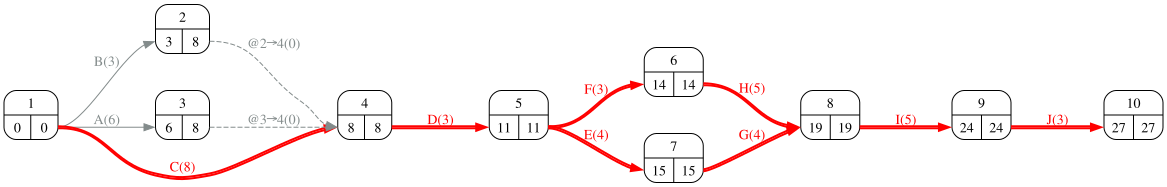

In [7]:
#| fig-cap: "Grafo PERT con tiempos de los nodos y camino crítico"
#| label: fig-pert
proyecto.pert(durations=datos_proyecto['duration'], ranksep=1)

In [8]:
#| tbl-cap: "Holgura total de las actividades"
#| label: tbl-holguras
resultados_pert = proyecto.calculate_pert(durations=datos_proyecto['duration'])
resultados_pert['activities'].T

,@2→4,@3→4,A,B,C,D,E,F,G,H,I,J
H_total,5,2,2,5,0,0,0,0,0,0,0,0


In [9]:
duracion_media = proyecto.duration(datos_proyecto['duration'])
rutas_criticas = proyecto.critical_path(datos_proyecto['duration'])
for nombre, acts in rutas_criticas.items():
    print(f'{nombre}: {" - ".join(acts)}')
Markdown(f'La duración media del proyecto es {duracion_media} semanas y tiene {len(rutas_criticas)} ruta(s) crítica(s).')

Route_5: C - D - E - G - I - J
Route_6: C - D - F - H - I - J


La duración media del proyecto es 27 semanas y tiene 2 ruta(s) crítica(s).

## Apartado 2

In [10]:
display(Markdown(pregunta_2))

2. Calcule la varianza y la desviación típica de la duración del proyecto. ¿Qué ruta crítica debe usarse para ello? Razone la respuesta.  

Por el teorema central del límite, la duración de una ruta es aproximadamente normal con media la suma de las medias y varianza la suma de las varianzas de sus actividades. Para el proyecto se toma la ruta crítica; si hay varias, la de mayor varianza, que es la hipótesis más prudente (la verdadera distribución del máximo de varias rutas no es normal, y el método PERT la aproxima así).

In [11]:
#| tbl-cap: "Varianza de las rutas críticas"
#| label: tbl-varianzaRutas
desviacion_proyecto, varianza_rutas = proyecto.standard_deviation(durations=datos_proyecto['duration'],
                                                                   variances=datos_proyecto['variance'])
varianza_rutas

,Activities,Variance
Route_5,"C, D, E, G, I, J",2.17
Route_6,"C, D, F, H, I, J",2.45


In [12]:
Markdown(f'La varianza del proyecto es {desviacion_proyecto**2:.3f} y su desviación típica {desviacion_proyecto:.3f} semanas.')

La varianza del proyecto es 2.450 y su desviación típica 1.565 semanas.

## Apartado 3

In [13]:
display(Markdown(pregunta_3))

3. ¿Qué probabilidad hay de terminar el proyecto en 29 semanas o menos?  

Con $T \sim N(\mu, \sigma)$: $P(T \le t) = \Phi\left(\frac{t - \mu}{\sigma}\right)$.

In [14]:
plazo = 29
z = (plazo - duracion_media) / desviacion_proyecto
probabilidad_plazo = norm.cdf(z)
Markdown(f'z = ({plazo} − {duracion_media}) / {desviacion_proyecto:.3f} = {z:.3f}, luego P(T ≤ {plazo}) = Φ({z:.3f}) = {probabilidad_plazo:.4f} ({probabilidad_plazo*100:.1f} %).')

z = (29 − 27) / 1.565 = 1.278, luego P(T ≤ 29) = Φ(1.278) = 0.8993 (89.9 %).

## Apartado 4

In [15]:
display(Markdown(pregunta_4))

4. ¿Qué probabilidad hay de terminar entre las semanas 26 y 29?  

In [16]:
t_a, t_b = 26, 29
p_b = norm.cdf((t_b - duracion_media) / desviacion_proyecto)
p_a = norm.cdf((t_a - duracion_media) / desviacion_proyecto)
Markdown(f'P({t_a} < T ≤ {t_b}) = Φ({(t_b - duracion_media) / desviacion_proyecto:.3f}) − Φ({(t_a - duracion_media) / desviacion_proyecto:.3f}) '
         f'= {p_b:.4f} − {p_a:.4f} = {p_b - p_a:.4f} ({(p_b - p_a)*100:.1f} %).')

P(26 < T ≤ 29) = Φ(1.278) − Φ(-0.639) = 0.8993 − 0.2615 = 0.6379 (63.8 %).

## Apartado 5

In [17]:
display(Markdown(pregunta_5))

5. ¿Qué duración puede comprometerse con el cliente con una probabilidad del 90% de cumplirla?  

Se busca $t$ tal que $P(T \le t) = p$, es decir, $t = \mu + z_p\,\sigma$ con $z_p = \Phi^{-1}(p)$.

In [18]:
probabilidad_objetivo = 0.9
z_p = norm.ppf(probabilidad_objetivo)
duracion_comprometida = duracion_media + z_p * desviacion_proyecto
Markdown(f'z = {z_p:.3f}; t = {duracion_media} + {z_p:.3f} × {desviacion_proyecto:.3f} = {duracion_comprometida:.2f} semanas. '
         f'Como el calendario se mide en semanas enteras, se comprometerían {int(np.ceil(duracion_comprometida))} semanas.')

z = 1.282; t = 27 + 1.282 × 1.565 = 29.01 semanas. Como el calendario se mide en semanas enteras, se comprometerían 30 semanas.

## Apartado 6

In [19]:
display(Markdown(pregunta_6))

6. ¿Qué probabilidad hay de terminar en la duración media o antes? ¿Puede garantizarse esa duración con un 90% de probabilidad sin modificar el proyecto?  

In [20]:
Markdown(f'''La duración media es la mediana de la normal, así que P(T ≤ {duracion_media}) = 0.5: sólo la mitad de las veces se terminaría en la duración media o antes. Para garantizarla con un 90% haría falta que la media del proyecto fuera {duracion_media} − {z_p:.3f} × {desviacion_proyecto:.3f} = {duracion_media - z_p * desviacion_proyecto:.2f} semanas, es decir, reducir el proyecto (acortando actividades críticas) o reducir su varianza. Sin tocar el proyecto no es posible.''')

La duración media es la mediana de la normal, así que P(T ≤ 27) = 0.5: sólo la mitad de las veces se terminaría en la duración media o antes. Para garantizarla con un 90% haría falta que la media del proyecto fuera 27 − 1.282 × 1.565 = 24.99 semanas, es decir, reducir el proyecto (acortando actividades críticas) o reducir su varianza. Sin tocar el proyecto no es posible.